# Solar filament segmentation: the whole pipeline

**Muhammad Elias Muhammadi**

This notebook goes through my solution step by step and ends with the submission file. It loads the
weights stored in `weights/`, so nothing is trained here. It needs the Kaggle bundle in
`data/MAGFiLO_1.0_Kaggle_2026/` and one GPU, and runs in about two minutes.

1. the training data, and how much the annotators disagree;
2. the network and the two keep-scorers;
3. one test frame through every step, with timing;
4. what the patch scorer looks at;
5. all 180 test frames and the submission file.

The method and every number behind it are in `report.pdf`.

In [1]:
FRAME = 42           # the test frame shown in sections 3 and 4

In [2]:
import json, sys, time, hashlib, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, cv2, matplotlib.pyplot as plt
from pycocotools import mask as mask_util

from filseg import submission
from filseg.config import load_config
from filseg.data import load_records, read_image, record_mask, solar_disk
from filseg.candidates import extract
from filseg.inference import on_disk, probability_map
from filseg.pipeline import Segmenter
from filseg.scorers import patches

cfg = load_config(ROOT / "config.yaml")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0))

torch 2.11.0+cu128 | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## 1. The training data

There are 707 training frames with 1,154 annotator records: 411 frames were drawn by one person, 145 by two
and 151 by three. The metric scores a prediction against every record of a frame separately, so on a frame
with three annotators the prediction has to agree with three people at once. Here is one such frame, with each
annotator in a different colour.

frames drawn by 1 / 2 / 3 annotators: 411 145 151 | records: 1154 | filaments: 8199


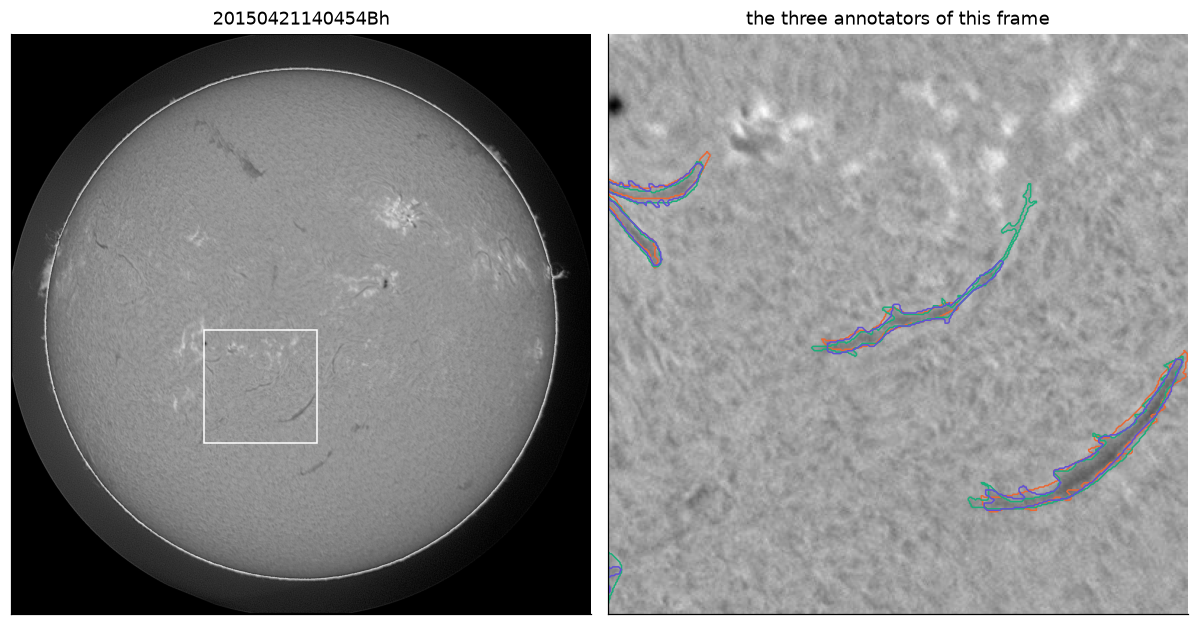

In [3]:
records = load_records(cfg)
counts = np.bincount([len(r) for r in records.values()])
print("frames drawn by 1 / 2 / 3 annotators:", counts[1], counts[2], counts[3],
      "| records:", sum(len(r) for r in records.values()),
      "| filaments:", sum(len(rec.polygons) for r in records.values() for rec in r))

stem = "20150421140454Bh"                          # a frame with three annotators
img = read_image(cfg["paths"]["train_images"] / f"{stem}.jpeg")
x0, y0, s = 680, 1044, 400
colours = ["#eb6834", "#1baf7a", "#6250d6"]
fig, ax = plt.subplots(1, 2, figsize=(11, 5.6))
ax[0].imshow(img, cmap="gray"); ax[0].add_patch(plt.Rectangle((x0, y0), s, s, fill=False, ec="w", lw=1))
ax[0].set_title(stem); ax[1].imshow(img[y0:y0 + s, x0:x0 + s], cmap="gray")
for c, rec in zip(colours, records[stem]):
    m = record_mask(rec)[y0:y0 + s, x0:x0 + s]
    for cnt in cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]:
        ax[1].plot(*np.vstack([cnt[:, 0], cnt[:1, 0]]).T, color=c, lw=1)
ax[1].set_title("the three annotators of this frame")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

The annotators agree on the dark cores and differ at the ends and on the faint filaments. Scored against each
other with the competition metric, two annotators of the same frame reach a PQ of only 0.34. This is the main
fact behind my design. The difficulty is not splitting pixels into instances (the connected components of an
annotator's own mask reproduce that annotator almost exactly), it is deciding which faint structures to keep.
So the network predicts the probability that an annotator marks a pixel, and two scorers decide which
components of that map to keep.

## 2. The network and the two keep-scorers

* **Network.** A U-Net with a ConvNeXt-T encoder, trained for 150 epochs on native 1024 px crops with the mean of
  the annotators' masks as target. It is fully convolutional, so it reads the whole 2048 x 2048 frame at once and
  nothing is ever downsampled. `weights/unet_full.safetensors` is trained on all 707 frames; the five fold models
  are there to reproduce the out-of-fold numbers.
* **Feature scorer.** Gradient-boosted trees on twenty numbers per candidate (`weights/feature_scorer.pkl`).
* **Patch scorer.** Three ResNet-18 networks that look at a 128 px patch of each candidate.

Both scorers estimate the IoU a candidate will reach against the annotators. A candidate is kept when the mean of
the two estimates is above tau, because only then does keeping it raise PQ.

In [4]:
segment = Segmenter(cfg)
net, rule, post = segment.net, segment.rule, segment.post
print(json.dumps(post, indent=1))
print("network parameters: %.1f M" % (sum(p.numel() for p in net.parameters()) / 1e6))

{
 "network": "unet_full.safetensors",
 "threshold": 0.8,
 "min_area": 30,
 "keep_tau": 0.25,
 "blend": 0.5,
 "feature_scorer": "feature_scorer.pkl",
 "patch_scorer": {
  "arch": "resnet18.a1_in1k",
  "files": [
   "patch_scorer_seed0.safetensors",
   "patch_scorer_seed1.safetensors",
   "patch_scorer_seed2.safetensors"
  ]
 },
 "out_of_fold_pq": 0.4586
}
network parameters: 31.9 M


## 3. One test frame, step by step

20121203063334Lh: 13 candidates, 6 kept
  network, 4 views            124 ms
  components and features     129 ms
  both scorers                276 ms


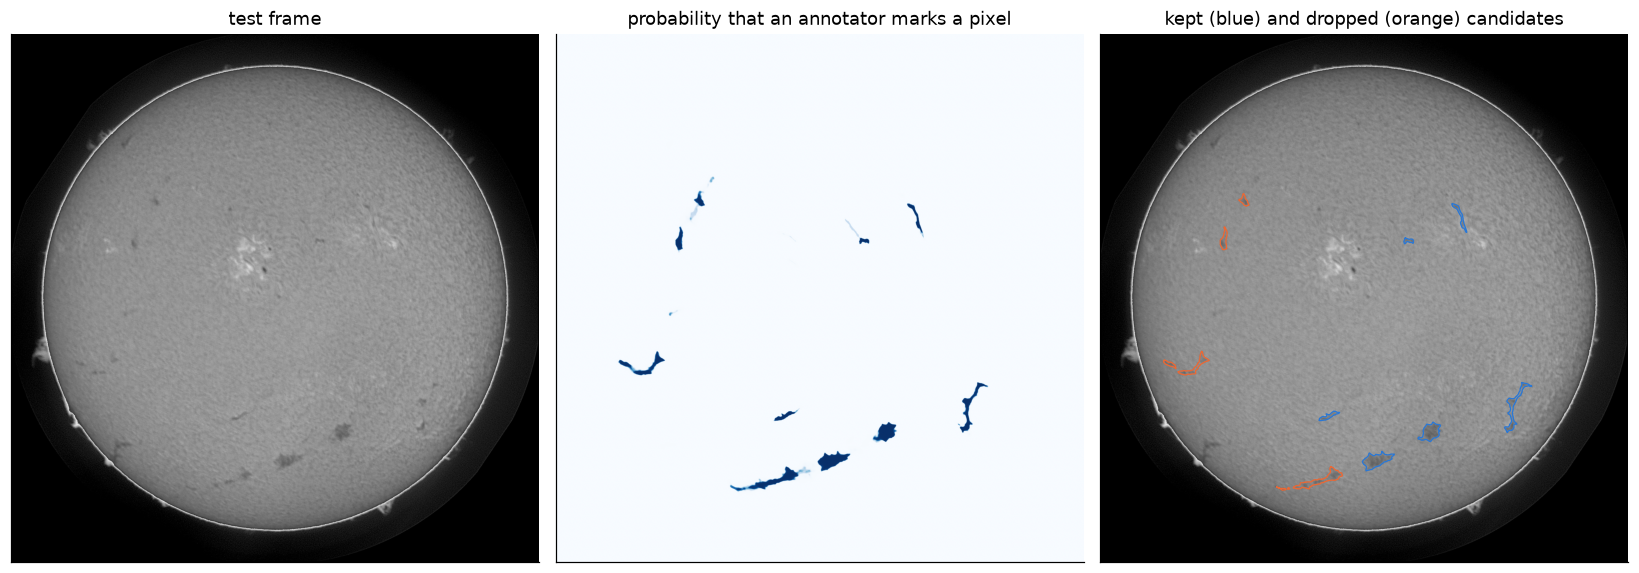

In [5]:
files = sorted(cfg["paths"]["test_images"].glob("*.jpeg"))
path = files[FRAME]
probability_map(net, read_image(files[0]), 1); torch.cuda.synchronize()     # warm-up, so the timing below is fair
t = [time.perf_counter()]
img = read_image(path); disk = solar_disk(img)
prob = on_disk(probability_map(net, img, cfg["predict"]["tta"]), disk); torch.cuda.synchronize(); t.append(time.perf_counter())
cands = extract(prob, img, disk, post["threshold"], post["min_area"]); t.append(time.perf_counter())
scores = rule.scores(img, prob, cands); t.append(time.perf_counter())
keep = scores > post["keep_tau"]
print(f"{path.stem}: {len(cands)} candidates, {keep.sum()} kept")
for name, a, b in zip(["network, 4 views", "components and features", "both scorers"], t[:-1], t[1:]):
    print(f"  {name:<24} {1000 * (b - a):6.0f} ms")

p = prob.cpu().numpy()
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("test frame")
ax[1].imshow(p, cmap="Blues", vmin=0, vmax=1); ax[1].set_title("probability that an annotator marks a pixel")
ax[2].imshow(img, cmap="gray"); ax[2].set_title("kept (blue) and dropped (orange) candidates")
for c, k in zip(cands, keep):
    m = mask_util.decode(c.mask_rle)
    for cnt in cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]:
        ax[2].plot(*np.vstack([cnt[:, 0], cnt[:1, 0]]).T, color="#2a78d6" if k else "#eb6834", lw=0.8)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

The threshold of 0.8 is high on purpose. The network is confident about real filaments, and a high cut gives
outlines that are close to the annotators'. What survives the threshold but should not be kept (small dark
specks, plage edges, pieces near the limb) is left to the scorers.

## 4. What the patch scorer looks at

Each candidate becomes a six-channel patch: the image, the probability map and the candidate's own mask, once in a
window of 1.5 times its bounding box and once in a window of four times it, both resized to 128 px. Below are the
image and mask channels of the four candidates the scorers are most and least sure about.

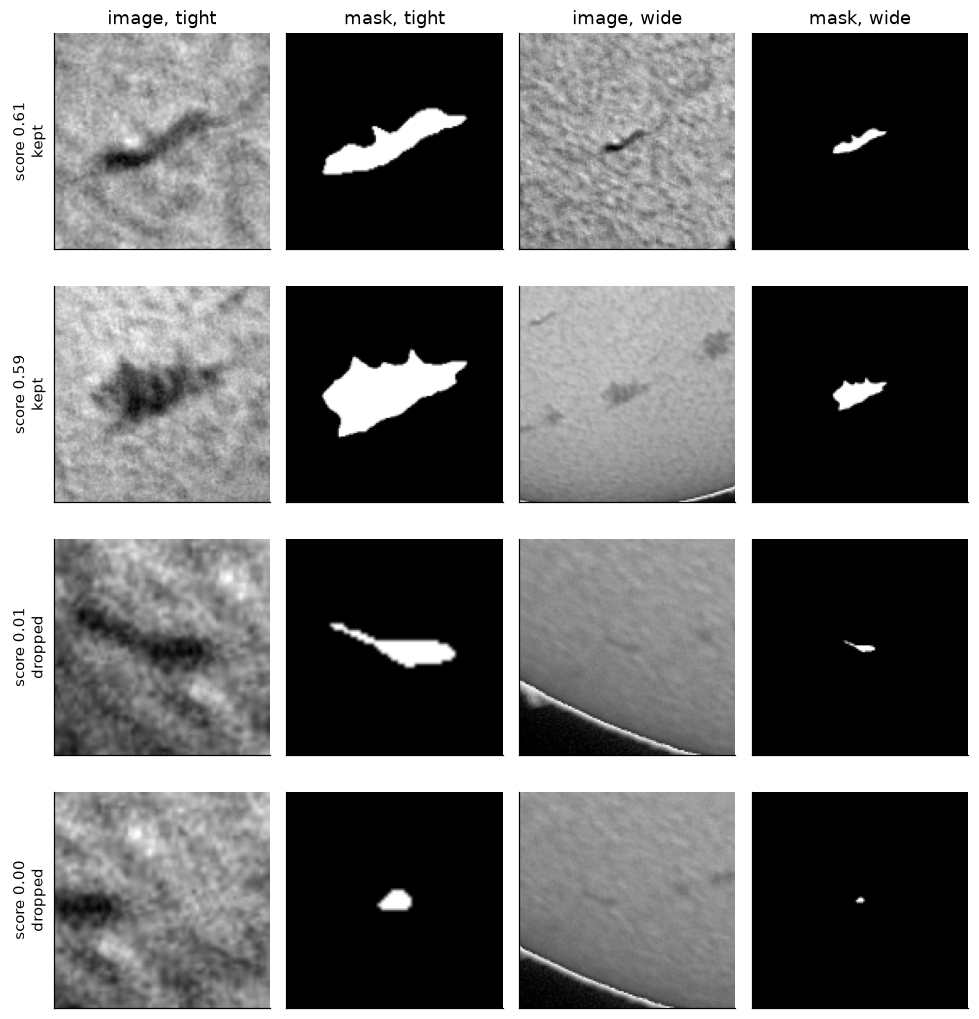

In [6]:
prob8 = (p * 255).round().astype(np.uint8)
P = patches(img, prob8, cands)
order = np.argsort(-scores)
pick = list(order[:2]) + list(order[-2:])
fig, ax = plt.subplots(len(pick), 4, figsize=(9, 2.4 * len(pick)))
for row, j in enumerate(pick):
    for col, (ch, name) in enumerate([(0, "image, tight"), (2, "mask, tight"), (3, "image, wide"), (5, "mask, wide")]):
        ax[row, col].imshow(P[j, ch], cmap="gray"); ax[row, col].set_xticks([]); ax[row, col].set_yticks([])
        if row == 0: ax[row, col].set_title(name)
    ax[row, 0].set_ylabel(f"score {max(scores[j], 0):.2f}\n{'kept' if keep[j] else 'dropped'}")
plt.tight_layout(); plt.show()

## 5. All test frames and the submission

The same steps for every test frame. Only the test image itself goes into the model. The file is checked for
everything the leaderboard rejects (repeated ids, unknown frames, quotes, empty or overlapping masks) and written
to `submission/submission.csv`.

In [7]:
rows, start = [], time.time()
for f in files:
    rows += submission.rows_for_frame(f.stem, [c.mask_rle for c in segment(read_image(f))])
seconds = (time.time() - start) / len(files)
out = cfg["paths"]["submission"]
df = submission.write(rows, out)
report = submission.check(df, [f.stem for f in files])
print(json.dumps(report, indent=1))
print(f"{seconds:.2f} s per frame | md5 {hashlib.md5(out.read_bytes()).hexdigest()}")
df.head()

{
 "filaments": 1117,
 "frames_with_filaments": 176,
 "frames_without": 4,
 "median_area_px": 1311.0
}
0.32 s per frame | md5 a0e0a4e8f9575d949a13337263e38b4a


,filament_id,segmentation_rle
0,20110120105534Ch_1,\_\h23mo12N4M1O00O101N2N100O02N2N2N1003M01O1hP...
1,20110120105534Ch_2,Zkdn14io13O2N001O00O001O0100O100001O0000O1000O...
2,20110130110334Ch_1,a_nd26io17I2N3N5K1UQNZO\n1e0aQN]Oan1a0^QN@dn1?...
3,20110214175414Mh_1,Z]d[26fo14N3N1O2H8N101N1POXOhRNi0Vm1ZOhRNf0Xm1...
4,20110214175414Mh_2,^^\d23lo12O1O1O001O0000001O010O1O1O000O0010O01...


## Results in short

Out-of-fold on the 707 training frames (every frame scored by models that never saw it), pooled over all 1,154
annotator records with the competition metric:

| | PQ |
|---|---|
| a second annotator of the same frame | 0.340 |
| connected components of the map, nothing dropped | 0.402 |
| with the feature scorer | 0.455 |
| with the mean of both scorers (this submission) | **0.459** |
| 90% bootstrap interval over frames | 0.451 to 0.467 |
| with perfect keep decisions (upper bound for any scorer) | 0.519 |

The matched filaments have a mean IoU of 0.68 and a mean Dice of 0.81; 2.3% of the annotated filaments are split
into several predicted masks and 2.8% of the predicted masks cover more than one filament. The report has the
distributions, the examples and the ideas that did not work.